In [1]:
modules = ["pandas", "numpy", "missingno", "seaborn", "matplotlib"]

import sys
import os.path
from subprocess import check_call
import importlib
import os

def instala(modules):
  print("Instalando módulos")
  for m in modules:
      # para el import quitamos [...] y ==...
      p = m.find("[")
      mi = m if p==-1 else m[:p]
      p = mi.find("==")
      mi = mi if p==-1 else mi[:p]

      torch_loader = importlib.util.find_spec(mi)
      if torch_loader is not None:
          print(m," encontrado")
      else:
          print(m," No encontrado, instalando...",end="")  
          try:        
            r = check_call([sys.executable, "-m", "pip", "install", "--user", m])
            print("¡hecho! (Reiniciar kernel)")
          except:
            print("¡Problema al instalar ",m,"! ¿seguro que el módulo existe?",sep="")
              
  print("¡Terminado!")

instala(modules)

Instalando módulos
pandas  encontrado
numpy  encontrado
missingno  encontrado
seaborn  encontrado
matplotlib  encontrado
¡Terminado!


In [2]:
import pandas as pd
import numpy as np
import missingno as msno
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
path = r'../../data/limpio_merged_data.csv'
df = pd.read_csv(path, header=0)
df

,timestamp,open_binance,high_binance,low_binance,close_binance,volume_binance,trades_binance,volumen_binance,SMA_50_binance,SMA_200_binance,...,mDvolatilidad_50_mDbinance,mDvolatilidad_200_mDbinance,mDrango_dia_mDbinance,mDmomentum_50_mDbinance,mDmomentum_200_mDbinance,mDSMA_50_mDbinance,mDSMA_200_mDbinance,mDEMA_50_mDbinance,mDEMA_200_mDbinance,mD_RSI_mDbinance
0,2022-03-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,606.7,NaN,NaN,NaN,NaN,39127.700000,39127.700000,NaN
1,2022-03-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,827.5,NaN,NaN,NaN,NaN,39137.401961,39130.161692,NaN
2,2022-03-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,345.1,NaN,NaN,NaN,NaN,39108.527374,39122.907346,NaN
3,2022-03-07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,829.8,NaN,NaN,NaN,NaN,39063.636105,39111.373940,NaN
4,2022-03-08,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,856.9,NaN,NaN,NaN,NaN,39049.764100,39107.379174,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1093,2025-03-01,84349.95,86558.00,83824.78,86064.53,25785.05464,3700728.0,2.219179e+09,97742.7420,82128.37695,...,5367.658728,17393.209564,2228.7,-8667.8,25457.2,97698.522,82109.0375,95256.733272,85612.086844,23.649004
1094,2025-03-02,86064.54,95000.00,85050.60,94270.00,54889.09045,7403218.0,5.174395e+09,97736.1422,82306.31000,...,5628.295132,17314.542268,340.2,-9191.0,26723.4,97514.702,82242.6545,94869.077066,85609.692945,24.587165
1095,2025-03-03,94269.99,94416.46,85117.11,86220.61,59171.10218,9797860.0,5.101769e+09,97569.6532,82449.70775,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1096,2025-03-04,86221.16,86807.98,82464.84,83756.58,20827.67236,4065252.0,1.744455e+09,97354.0628,82574.11765,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 1. Conteo de nulos

<Axes: >

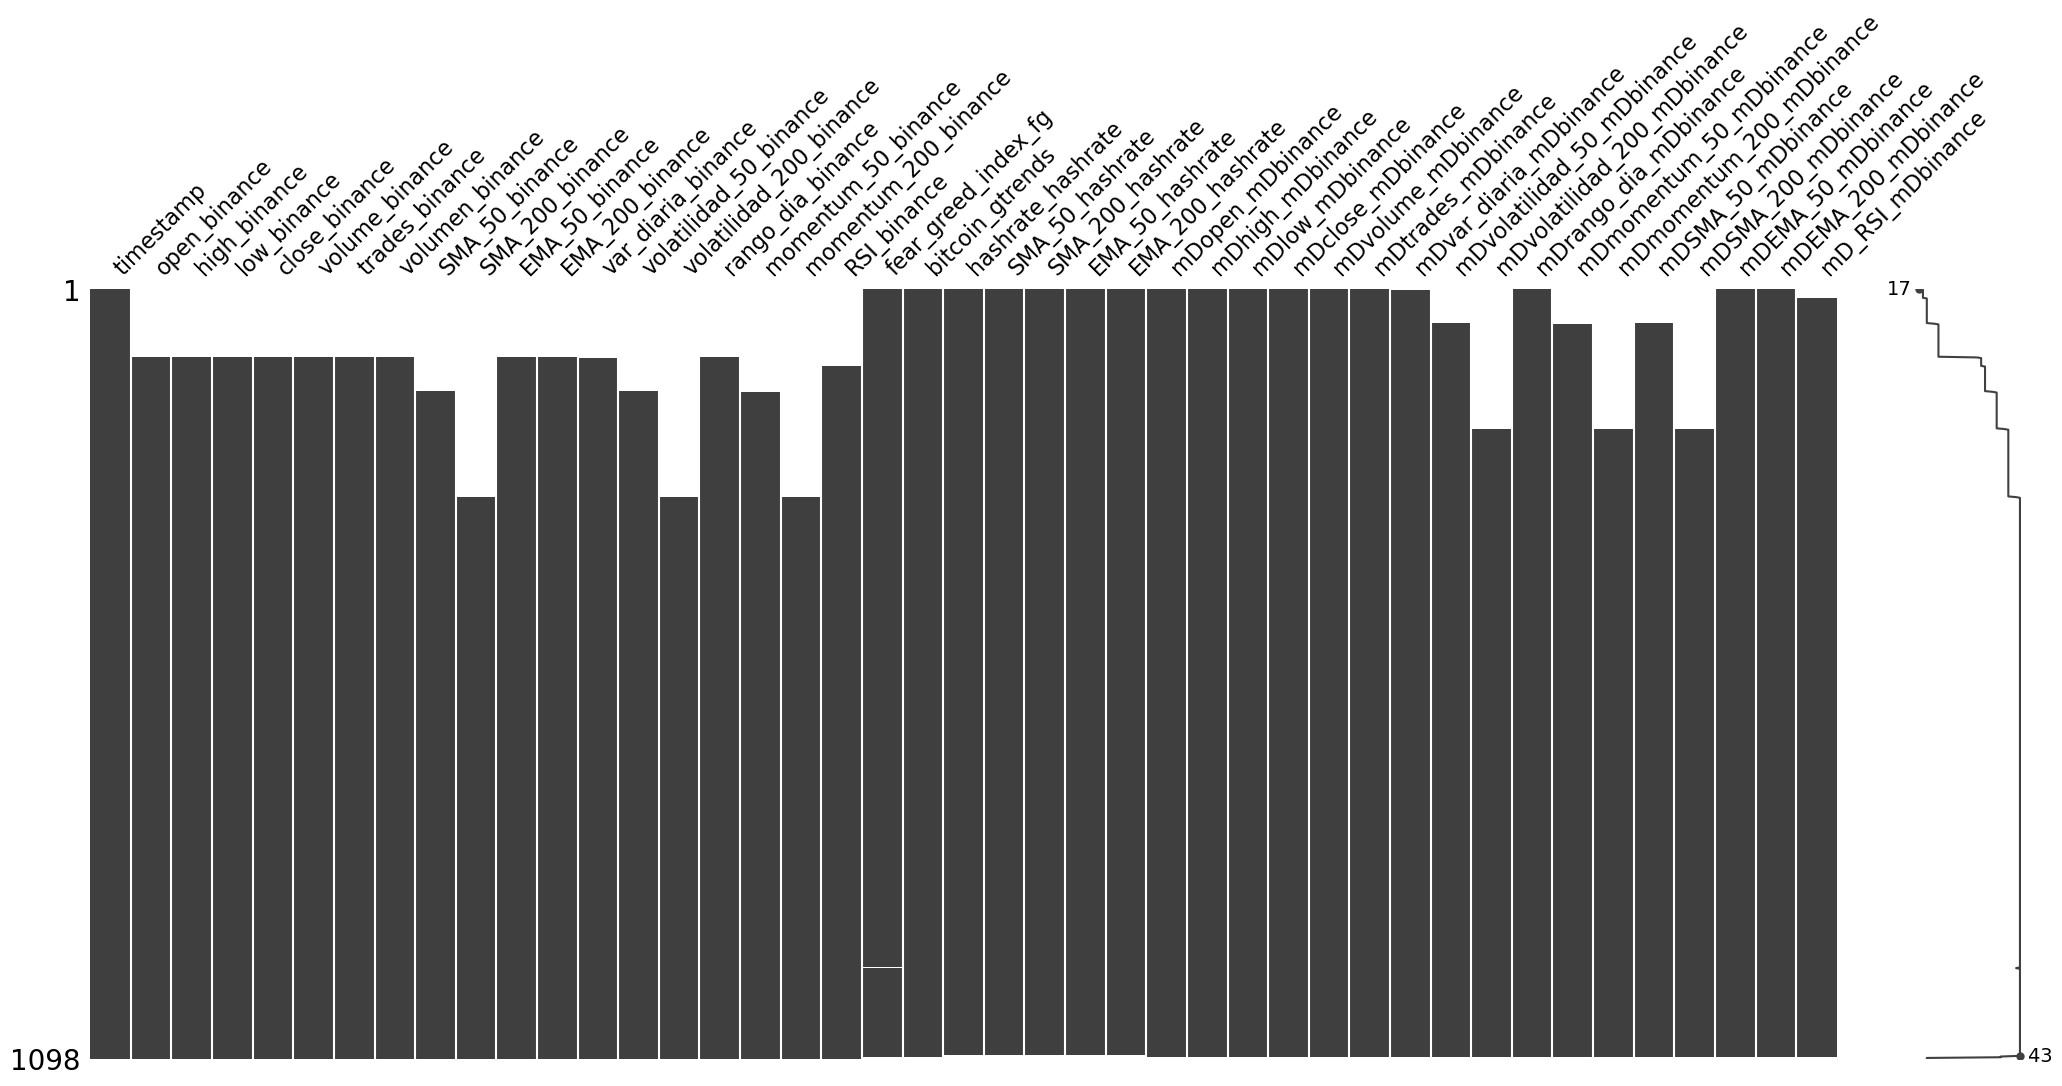

In [4]:
msno.matrix(df)

## 2. Correlaciones

In [5]:
# 1. Convertir la columna 'timestamp' a tipo datetime
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 2. Establecer 'timestamp' como índice
df.set_index('timestamp', inplace=True)

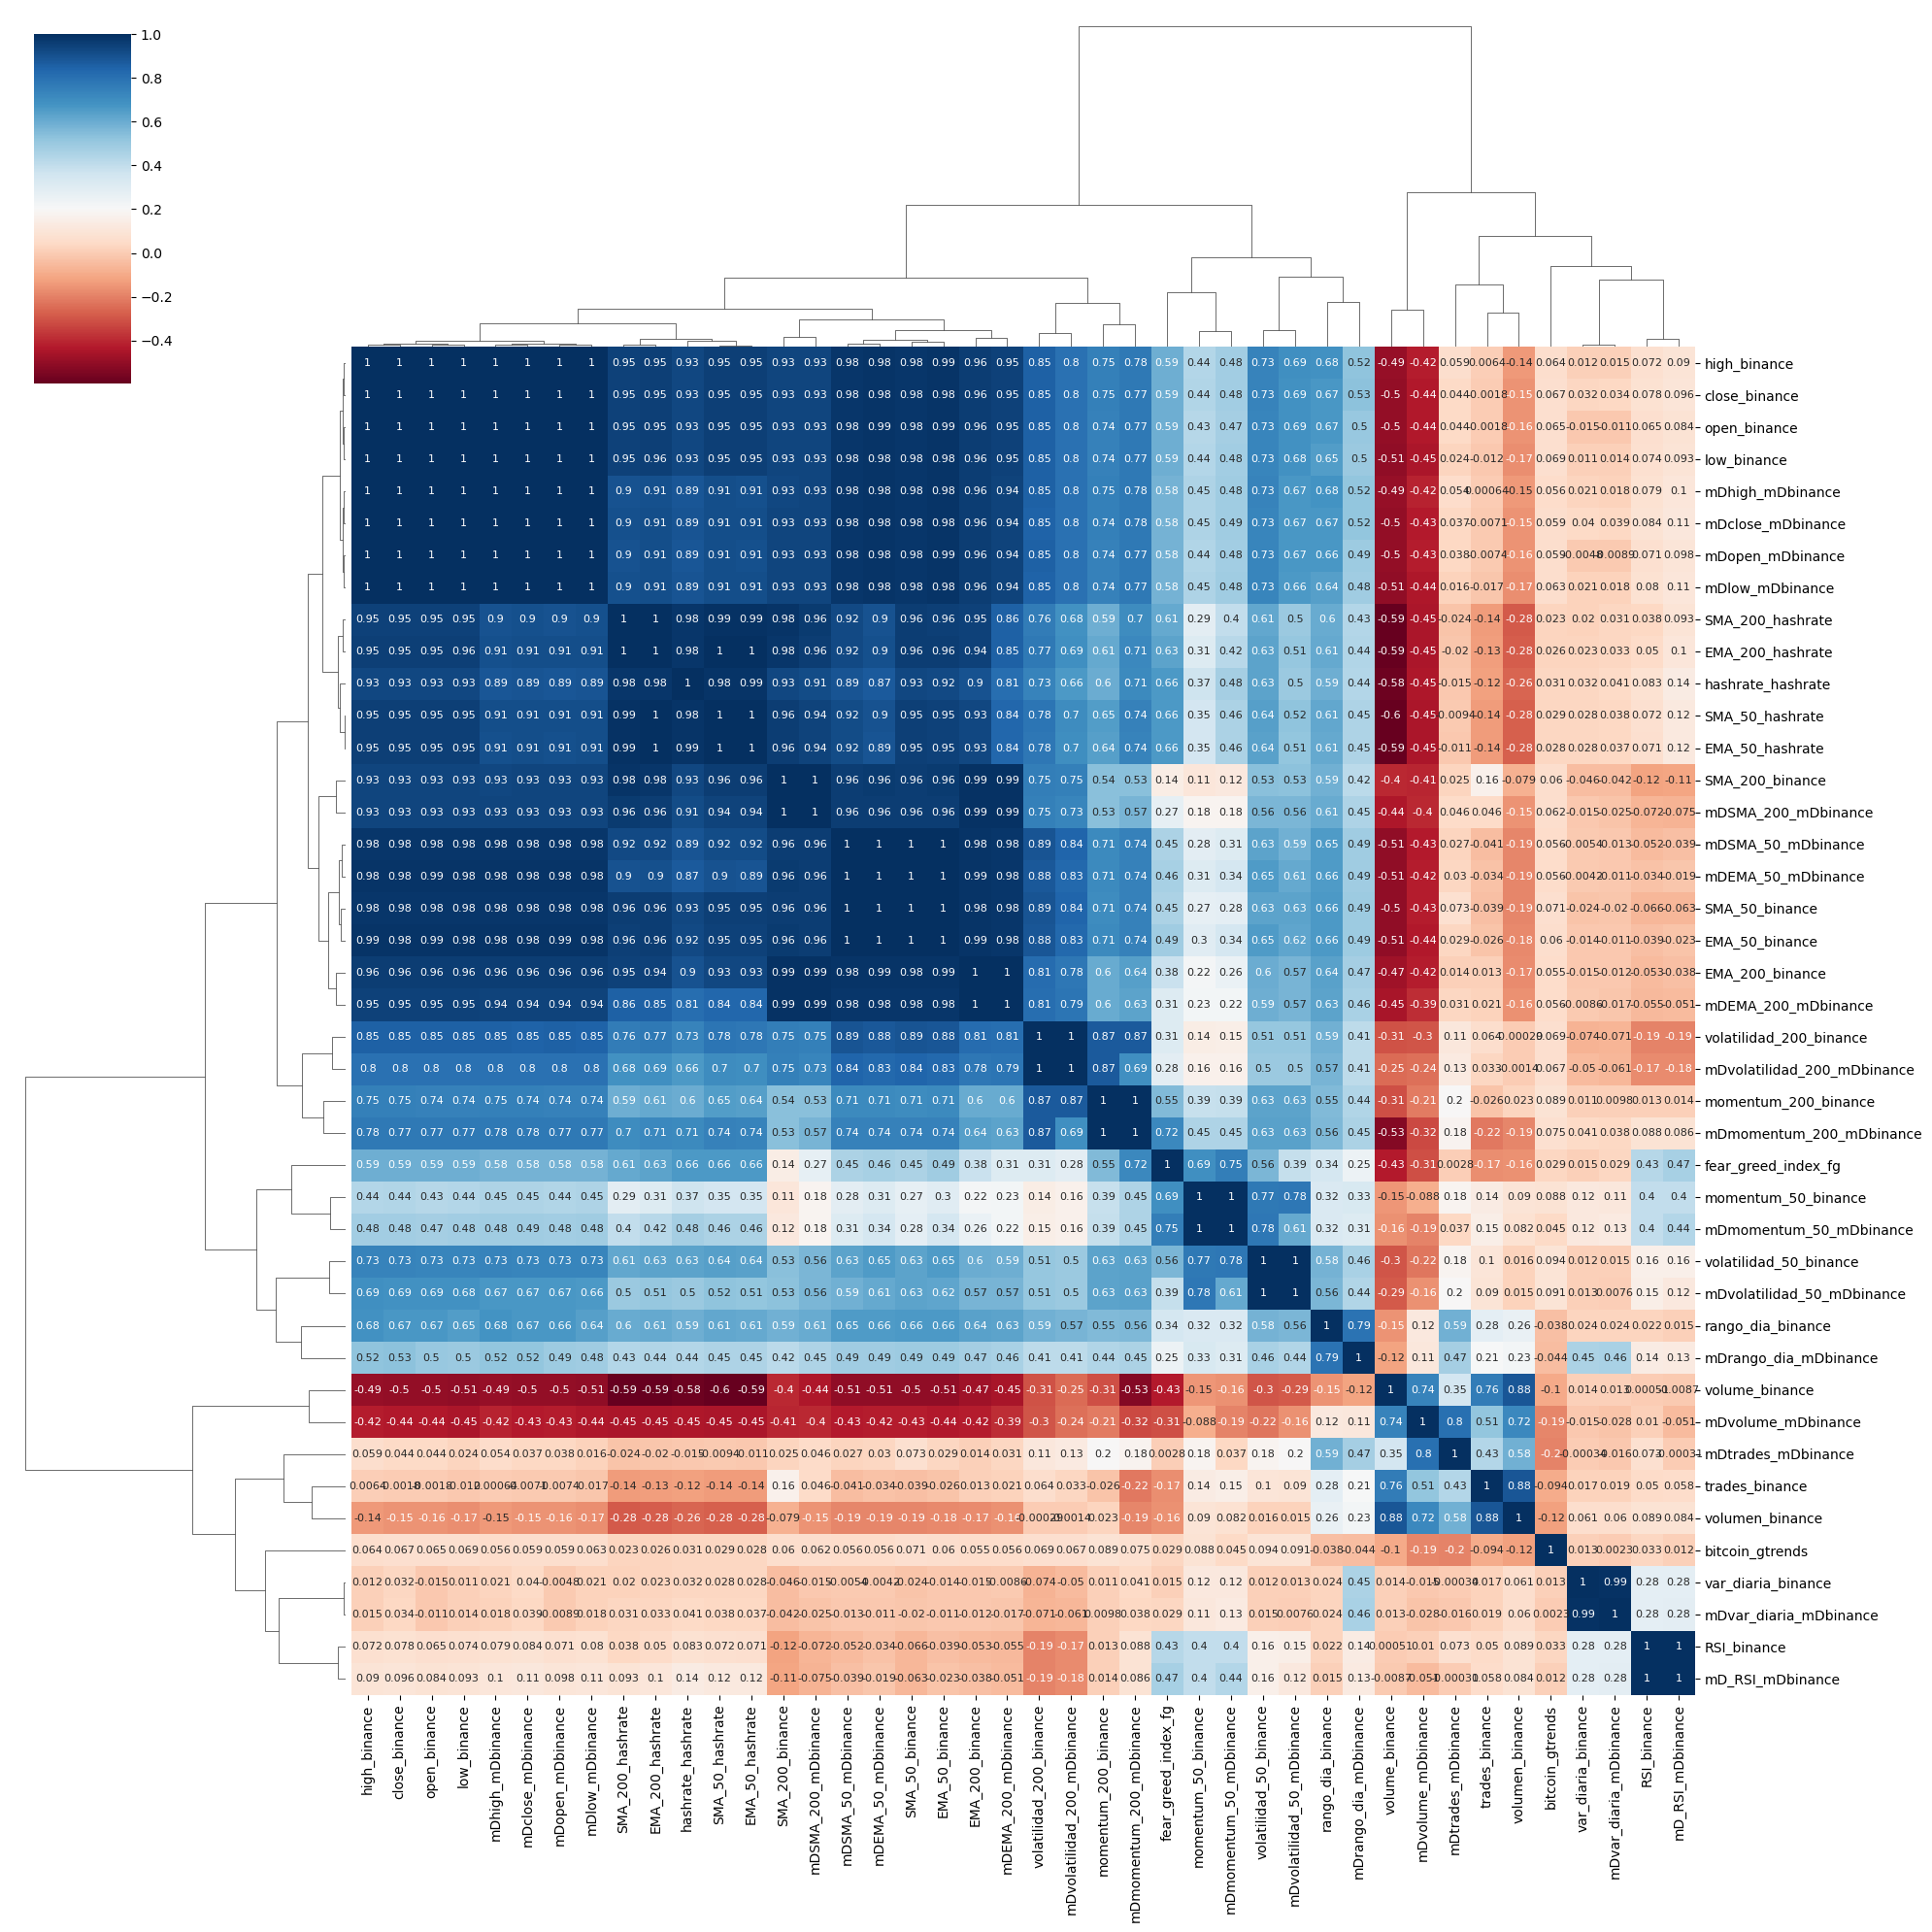

In [6]:
# 3. Calcular las correlaciones de las series temporales
corr_matrix = df.corr()

# 4. Aplicar clustermap de la correlación
g = sns.clustermap(corr_matrix, 
                   method='complete',  # Método de enlace para la jerarquía
                   cmap='RdBu',         # Colormap
                   annot=True,          # Mostrar los valores de correlación en el mapa
                   annot_kws={'size': 8}, # Tamaño de la fuente de las anotaciones
                   figsize=(20, 20))     # Tamaño de la figura

# Mostrar el gráfico
plt.show()